In [1]:
# ==========================================
# 1. 기본 설정
# ==========================================
import os, time, math
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🖥️ 현재 사용 중인 장치: {device}\n")


🖥️ 현재 사용 중인 장치: cuda



In [2]:
# ==========================================
# 2. CIFAR-100 데이터 로드 (Kaggle 내장 다운로드 — 구글 드라이브 불필요)
# ==========================================
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)),
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)),
])

train_dataset = datasets.CIFAR100(root='/kaggle/working/data', train=True,  download=True, transform=transform_train)
test_dataset  = datasets.CIFAR100(root='/kaggle/working/data', train=False, download=True, transform=transform_test)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=128, shuffle=False, num_workers=2)

print(f"📊 학습 데이터: {len(train_dataset)}장 | 테스트 데이터: {len(test_dataset)}장 준비 완료\n")


100%|██████████| 169M/169M [40:40<00:00, 69.2kB/s]


📊 학습 데이터: 50000장 | 테스트 데이터: 10000장 준비 완료



In [3]:
# ==========================================
# 3. 모델 빌더 (ResNet-18 for CIFAR-100)
# ==========================================
def build_model():
    m = models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 100)
    return m.to(device)

print("✅ 모델 빌더 정의 완료!\n")


✅ 모델 빌더 정의 완료!



In [4]:
# ==========================================
# 4. Muon 옵티마이저 (07_muon_sam_v3.ipynb와 동일)
# ==========================================
@torch.no_grad()
def zeropower_via_newtonschulz5(G, steps=5, eps=1e-7):
    assert len(G.shape) == 2
    a, b, c = (3.4445, -4.7750,  2.0315)
    X = G.bfloat16()
    X /= (X.norm() + eps)
    if G.size(0) > G.size(1):
        X = X.T
    for _ in range(steps):
        A = X @ X.T
        B = b * A + c * A @ A
        X = a * X + B @ X
    if G.size(0) > G.size(1):
        X = X.T
    return X.to(G.dtype)

class Muon(optim.Optimizer):
    def __init__(self, params, lr=0.02, momentum=0.95, nesterov=True, ns_steps=5):
        defaults = dict(lr=lr, momentum=momentum, nesterov=nesterov, ns_steps=ns_steps)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            for p in group['params']:
                g = p.grad
                if g is None:
                    continue
                state = self.state[p]
                if 'momentum_buffer' not in state:
                    state['momentum_buffer'] = torch.zeros_like(g)
                buf = state['momentum_buffer']

                original_shape = g.shape
                if g.ndim > 2:
                    g = g.view(g.size(0), -1)

                g_ortho = zeropower_via_newtonschulz5(g, steps=group['ns_steps'])
                g_ortho = g_ortho.view(original_shape)

                buf.mul_(group['momentum']).add_(g_ortho)
                if group['nesterov']:
                    g_update = g_ortho + group['momentum'] * buf
                else:
                    g_update = buf

                p.add_(g_update, alpha=-group['lr'])
        return loss

print("✅ Muon 옵티마이저 정의 완료!\n")


✅ Muon 옵티마이저 정의 완료!



In [5]:
# ==========================================
# 5. Lion 옵티마이저
# ==========================================
class Lion(optim.Optimizer):
    def __init__(self, params, lr=1e-4, betas=(0.9, 0.99), weight_decay=0.0):
        defaults = dict(lr=lr, betas=betas, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad
                state = self.state[p]
                if len(state) == 0:
                    state['exp_avg'] = torch.zeros_like(p)
                exp_avg = state['exp_avg']

                # decoupled weight decay
                p.mul_(1 - group['lr'] * group['weight_decay'])

                # c = beta1*m + (1-beta1)*g -> sign(c)가 실제 업데이트 방향
                update = exp_avg.mul(beta1).add(grad, alpha=1 - beta1).sign_()
                p.add_(update, alpha=-group['lr'])

                # 모멘텀은 beta2로 별도 갱신
                exp_avg.mul_(beta2).add_(grad, alpha=1 - beta2)
        return loss

print("✅ Lion 옵티마이저 정의 완료!\n")


✅ Lion 옵티마이저 정의 완료!



In [6]:
# ==========================================
# 6. SAMAscent (v3와 동일) + WSD 스케줄 함수
# ==========================================
class SAMAscent:
    """SAM을 '옵티마이저'가 아니라 '그래디언트 변환기'로 분리한 것 (v3 설계 그대로)."""
    def __init__(self, params, rho=0.05):
        self.params = [p for p in params if p.requires_grad]
        self.rho = rho
        self._e_w = {}

    def set_rho(self, rho):
        self.rho = rho

    @torch.no_grad()
    def _grad_norm(self):
        grads = [p.grad.norm(p=2) for p in self.params if p.grad is not None]
        if not grads:
            return torch.tensor(0.0)
        return torch.norm(torch.stack(grads), p=2)

    @torch.no_grad()
    def ascent(self):
        if self.rho <= 0:
            return False
        grad_norm = self._grad_norm()
        if grad_norm.item() < 1e-12:
            return False
        scale = self.rho / (grad_norm + 1e-12)
        self._e_w.clear()
        for p in self.params:
            if p.grad is None:
                continue
            e_w = p.grad * scale.to(p.device)
            p.add_(e_w)
            self._e_w[p] = e_w
        return True

    @torch.no_grad()
    def restore(self):
        for p, e_w in self._e_w.items():
            p.sub_(e_w)
        self._e_w.clear()


def wsd_scale(epoch, total_epochs, warmup_frac=0.1, decay_frac=0.2):
    """Warmup-Stable-Decay 스케줄. lr 배율(0~1)과 '지금이 decay 구간인지'를 반환.
    SAM은 decay 구간에서만 켜진다 (최종 보고서 설계와 동일)."""
    warmup_epochs = max(1, int(total_epochs * warmup_frac))
    decay_epochs  = max(1, int(total_epochs * decay_frac))
    stable_epochs = total_epochs - warmup_epochs - decay_epochs

    if epoch < warmup_epochs:
        scale = (epoch + 1) / warmup_epochs
        in_decay = False
    elif epoch < warmup_epochs + stable_epochs:
        scale = 1.0
        in_decay = False
    else:
        t = (epoch - warmup_epochs - stable_epochs + 1) / decay_epochs
        t = min(1.0, t)
        scale = 0.5 * (1 + math.cos(math.pi * t))
        in_decay = True
    return scale, in_decay

print("✅ SAMAscent + WSD 스케줄 정의 완료!\n")


✅ SAMAscent + WSD 스케줄 정의 완료!



In [7]:
# ==========================================
# 7. 평가 함수 + 옵티마이저 빌더 + 단일 실험 실행 함수
# ==========================================
def evaluate(model_to_eval, loader):
    model_to_eval.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model_to_eval(inputs)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
    return 100. * correct / total


def build_optimizers(opt_name, model):
    """옵티마이저 이름에 따라 (옵티마이저, base_lr) 리스트를 반환.
    muon만 예외적으로 두 개(Muon + AdamW)를 같이 씀 — conv1/fc는 AdamW가 담당."""
    if opt_name == 'muon':
        muon_params, other_params = [], []
        for name, p in model.named_parameters():
            if p.ndim >= 2 and name not in ('conv1.weight', 'fc.weight'):
                muon_params.append(p)
            else:
                other_params.append(p)
        opt_muon  = Muon(muon_params, lr=0.02, momentum=0.95)
        opt_other = optim.AdamW(other_params, lr=3e-4, weight_decay=0.01)
        return [(opt_muon, 0.02), (opt_other, 3e-4)]
    elif opt_name == 'sgd':
        opt = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
        return [(opt, 0.1)]
    elif opt_name == 'adamw':
        opt = optim.AdamW(model.parameters(), lr=0.01, weight_decay=0.01)
        return [(opt, 0.01)]
    elif opt_name == 'lion':
        opt = Lion(model.parameters(), lr=3e-4, weight_decay=0.01)
        return [(opt, 3e-4)]
    else:
        raise ValueError(f"알 수 없는 옵티마이저: {opt_name}")


def set_lr(optimizers, scale):
    for opt, base_lr in optimizers:
        for g in opt.param_groups:
            g['lr'] = base_lr * scale


def run_experiment(opt_name, sam_mode, epochs, rho=0.05, seed=0):
    """opt_name: 'sgd'|'adamw'|'lion'|'muon'  /  sam_mode: 'off'|'decay'"""
    torch.manual_seed(seed)
    model = build_model()
    optimizers = build_optimizers(opt_name, model)
    sam = SAMAscent(model.parameters(), rho=0.0)
    criterion = nn.CrossEntropyLoss()

    history = []
    print(f"\n🚀 시작: optimizer={opt_name}, sam={sam_mode}, {epochs} epochs")

    for epoch in range(epochs):
        scale, in_decay = wsd_scale(epoch, epochs)
        set_lr(optimizers, scale)
        rho_now = rho if (sam_mode == 'decay' and in_decay) else 0.0
        sam.set_rho(rho_now)

        model.train()
        running_loss, correct, total, n_batches = 0.0, 0, 0, 0
        start_time = time.time()

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            for opt, _ in optimizers:
                opt.zero_grad(set_to_none=True)

            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()

            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

            if sam.ascent():
                for opt, _ in optimizers:
                    opt.zero_grad(set_to_none=True)
                loss_adv = criterion(model(inputs), targets)
                loss_adv.backward()
                sam.restore()

            for opt, _ in optimizers:
                opt.step()

            running_loss += loss.item()
            n_batches += 1

        epoch_time = time.time() - start_time
        train_loss = running_loss / n_batches
        train_acc = 100. * correct / total
        test_acc = evaluate(model, test_loader)

        history.append({'epoch': epoch + 1, 'lr_scale': scale, 'in_decay': in_decay,
                         'rho': rho_now, 'train_loss': train_loss,
                         'train_acc': train_acc, 'test_acc': test_acc, 'time': epoch_time})

        print(f"  [{opt_name}/{sam_mode}] Ep [{epoch+1}/{epochs}] | {epoch_time:.1f}s | "
              f"Loss: {train_loss:.4f} | Train: {train_acc:.2f}% | Test: {test_acc:.2f}% | rho={rho_now:.3f}")

    df_hist = pd.DataFrame(history)
    hist_path = f'/kaggle/working/history_{opt_name}_{sam_mode}.csv'
    df_hist.to_csv(hist_path, index=False)

    result = {
        'optimizer': opt_name,
        'sam': sam_mode,
        'final_train_acc': history[-1]['train_acc'],
        'final_test_acc': history[-1]['test_acc'],
        'best_test_acc': max(h['test_acc'] for h in history),
        'total_time_min': round(sum(h['time'] for h in history) / 60, 1),
    }
    return result

print("✅ 실험 실행 함수 정의 완료!\n")


✅ 실험 실행 함수 정의 완료!



In [8]:
# ==========================================
# 8. 메인 루프 — 8개 run을 모드 전환 없이 자동으로 순차 실행
#    (여기만 실행하면 끝. MODE 변수 손댈 필요 없음)
# ==========================================
EPOCHS = 30          # 필요하면 여기 숫자만 바꾸세요 (S0 파일럿과 동일 규모가 30)
RHO = 0.05
RESULTS_PATH = '/kaggle/working/summary_all.csv'

CONFIGS = [
    ('sgd',   'off'), ('sgd',   'decay'),
    ('adamw', 'off'), ('adamw', 'decay'),
    ('lion',  'off'), ('lion',  'decay'),
    ('muon',  'off'), ('muon',  'decay'),
]

all_results = []
for opt_name, sam_mode in CONFIGS:
    result = run_experiment(opt_name, sam_mode, epochs=EPOCHS, rho=RHO)
    all_results.append(result)
    pd.DataFrame(all_results).to_csv(RESULTS_PATH, index=False)
    print(f"✅ 저장됨: {RESULTS_PATH}  (지금까지 {len(all_results)}/{len(CONFIGS)}개 완료)\n")

print("\n🎉 전체 8개 run 완료!")



🚀 시작: optimizer=sgd, sam=off, 30 epochs
  [sgd/off] Ep [1/30] | 19.8s | Loss: 3.9360 | Train: 10.19% | Test: 16.74% | rho=0.000
  [sgd/off] Ep [2/30] | 19.1s | Loss: 3.4244 | Train: 17.68% | Test: 22.38% | rho=0.000
  [sgd/off] Ep [3/30] | 19.7s | Loss: 3.1469 | Train: 22.21% | Test: 26.20% | rho=0.000
  [sgd/off] Ep [4/30] | 20.4s | Loss: 2.8572 | Train: 27.48% | Test: 30.64% | rho=0.000
  [sgd/off] Ep [5/30] | 21.2s | Loss: 2.6826 | Train: 30.85% | Test: 30.09% | rho=0.000
  [sgd/off] Ep [6/30] | 22.1s | Loss: 2.5565 | Train: 33.59% | Test: 34.27% | rho=0.000
  [sgd/off] Ep [7/30] | 23.2s | Loss: 2.4664 | Train: 35.74% | Test: 36.21% | rho=0.000
  [sgd/off] Ep [8/30] | 22.1s | Loss: 2.3881 | Train: 37.02% | Test: 35.61% | rho=0.000
  [sgd/off] Ep [9/30] | 21.9s | Loss: 2.3206 | Train: 38.81% | Test: 37.72% | rho=0.000
  [sgd/off] Ep [10/30] | 22.3s | Loss: 2.2700 | Train: 39.69% | Test: 38.65% | rho=0.000
  [sgd/off] Ep [11/30] | 22.3s | Loss: 2.2150 | Train: 41.07% | Test: 36.43% |

In [9]:
# ==========================================
# 9. 최종 결과 요약 — SAM 켰을 때 정확도가 얼마나 (안) 바뀌는지 한눈에 확인
# ==========================================
df = pd.DataFrame(all_results)
pivot = df.pivot(index='optimizer', columns='sam', values='final_test_acc')
pivot['diff (decay - off)'] = (pivot['decay'] - pivot['off']).round(2)
print(pivot.round(2))
print(f"\n결과 CSV: {RESULTS_PATH}")
print("각 run의 epoch별 상세 기록: /kaggle/working/history_<optimizer>_<sam>.csv")


sam        decay    off  diff (decay - off)
optimizer                                  
adamw      55.10  55.08                0.02
lion       54.17  54.17                0.00
muon       57.78  57.93               -0.15
sgd        58.74  59.08               -0.34

결과 CSV: /kaggle/working/summary_all.csv
각 run의 epoch별 상세 기록: /kaggle/working/history_<optimizer>_<sam>.csv


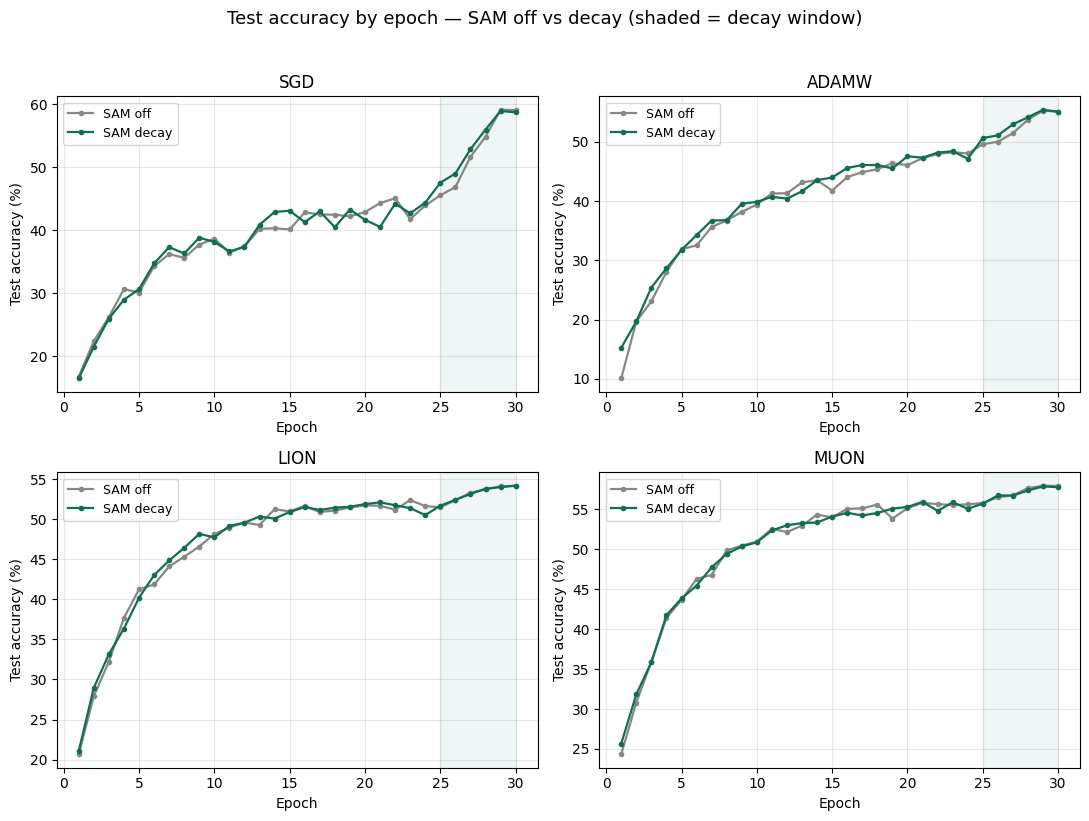

In [10]:
# ==========================================
# 10-1. 학습 곡선 — 옵티마이저별 SAM off vs decay
# ==========================================
import matplotlib.pyplot as plt

os.makedirs('/kaggle/working/figures', exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
optimizers = ['sgd', 'adamw', 'lion', 'muon']
mode_color = {'off': '#888780', 'decay': '#0F6E56'}

for ax, opt_name in zip(axes.ravel(), optimizers):
    for sam_mode in ['off', 'decay']:
        hist = pd.read_csv(f'/kaggle/working/history_{opt_name}_{sam_mode}.csv')
        ax.plot(hist['epoch'], hist['test_acc'], color=mode_color[sam_mode],
                marker='o', markersize=3, lw=1.6, label=f'SAM {sam_mode}')
        # decay 구간이 시작되는 지점에 배경 음영 표시
        decay_start = hist.loc[hist['in_decay'], 'epoch'].min()
        if pd.notna(decay_start) and sam_mode == 'decay':
            ax.axvspan(decay_start, hist['epoch'].max(), color='#0F6E56', alpha=0.06)
    ax.set_title(opt_name.upper(), fontsize=12)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Test accuracy (%)')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

fig.suptitle('Test accuracy by epoch — SAM off vs decay (shaded = decay window)', fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig('/kaggle/working/figures/learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()


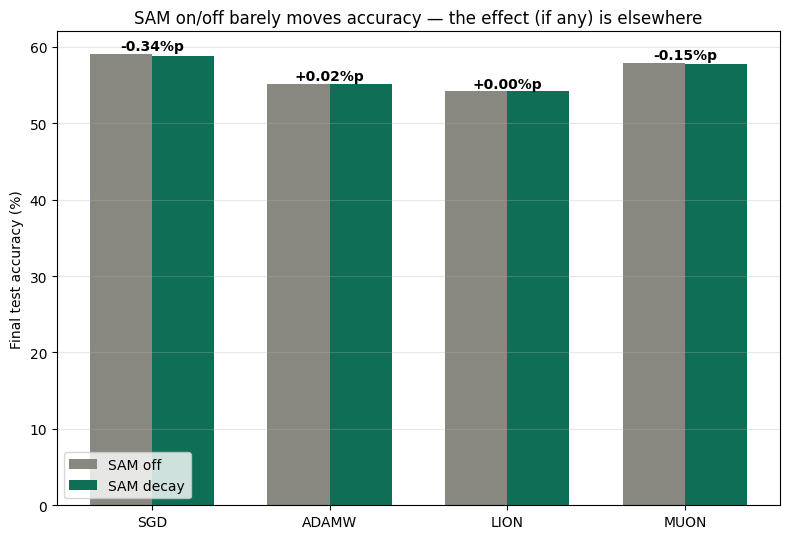

저장된 그림: /kaggle/working/figures/learning_curves.png, off_vs_decay_bar.png


In [11]:
# ==========================================
# 10-2. 막대그래프 — 최종 정확도 off vs decay, 차이(%p) 라벨 표시
# ==========================================
import numpy as np

fig, ax = plt.subplots(figsize=(8, 5.5))
x = np.arange(len(optimizers))
width = 0.35

off_accs   = [pivot.loc[o, 'off'] for o in optimizers]
decay_accs = [pivot.loc[o, 'decay'] for o in optimizers]

ax.bar(x - width/2, off_accs,   width, label='SAM off',   color='#888780')
ax.bar(x + width/2, decay_accs, width, label='SAM decay', color='#0F6E56')

for i, (o, d) in enumerate(zip(off_accs, decay_accs)):
    diff = d - o
    y_top = max(o, d) + 0.5
    ax.annotate(f'{diff:+.2f}%p', xy=(i, y_top), ha='center', fontsize=10, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels([o.upper() for o in optimizers])
ax.set_ylabel('Final test accuracy (%)')
ax.set_title('SAM on/off barely moves accuracy — the effect (if any) is elsewhere', fontsize=12)
ax.legend()
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig('/kaggle/working/figures/off_vs_decay_bar.png', dpi=150, bbox_inches='tight')
plt.show()

print("저장된 그림: /kaggle/working/figures/learning_curves.png, off_vs_decay_bar.png")
